In [1]:
import pandas as pd
import numpy as np

In [2]:
import zipfile

with zipfile.ZipFile("bike-sharing-demand.zip", "r") as zip_ref:
    zip_ref.extractall("bike_sharing_data")

In [3]:
train = pd.read_csv("bike_sharing_data/train.csv")
test = pd.read_csv("bike_sharing_data/test.csv")
sample_submission = pd.read_csv("bike_sharing_data/sampleSubmission.csv")

In [4]:
train.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [5]:
print("Training dataset shape:", train.shape)
print("Testing dataset shape:", test.shape)

Training dataset shape: (10886, 12)
Testing dataset shape: (6493, 9)


In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  object 
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 1020.7+ KB


In [7]:
train.isnull().sum()

datetime      0
season        0
holiday       0
workingday    0
weather       0
temp          0
atemp         0
humidity      0
windspeed     0
casual        0
registered    0
count         0
dtype: int64

In [8]:
train.describe()

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
count,10886.000000,10886.000000,10886.000000,10886.000000,10886.00000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000
mean,2.506614,0.028569,0.680875,1.418427,20.23086,23.655084,61.886460,12.799395,36.021955,155.552177,191.574132
std,1.116174,0.166599,0.466159,0.633839,7.79159,8.474601,19.245033,8.164537,49.960477,151.039033,181.144454
min,1.000000,0.000000,0.000000,1.000000,0.82000,0.760000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,0.000000,1.000000,13.94000,16.665000,47.000000,7.001500,4.000000,36.000000,42.000000
50%,3.000000,0.000000,1.000000,1.000000,20.50000,24.240000,62.000000,12.998000,17.000000,118.000000,145.000000
75%,4.000000,0.000000,1.000000,2.000000,26.24000,31.060000,77.000000,16.997900,49.000000,222.000000,284.000000
max,4.000000,1.000000,1.000000,4.000000,41.00000,45.455000,100.000000,56.996900,367.000000,886.000000,977.000000


Q1. Examine dataset size, missing values, and feature types.

In [9]:
train.shape
train.info()
train.isnull().sum()
train.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  object 
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 1020.7+ KB


,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
count,10886.000000,10886.000000,10886.000000,10886.000000,10886.00000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000
mean,2.506614,0.028569,0.680875,1.418427,20.23086,23.655084,61.886460,12.799395,36.021955,155.552177,191.574132
std,1.116174,0.166599,0.466159,0.633839,7.79159,8.474601,19.245033,8.164537,49.960477,151.039033,181.144454
min,1.000000,0.000000,0.000000,1.000000,0.82000,0.760000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,0.000000,1.000000,13.94000,16.665000,47.000000,7.001500,4.000000,36.000000,42.000000
50%,3.000000,0.000000,1.000000,1.000000,20.50000,24.240000,62.000000,12.998000,17.000000,118.000000,145.000000
75%,4.000000,0.000000,1.000000,2.000000,26.24000,31.060000,77.000000,16.997900,49.000000,222.000000,284.000000
max,4.000000,1.000000,1.000000,4.000000,41.00000,45.455000,100.000000,56.996900,367.000000,886.000000,977.000000


The training dataset contains 10,886 observations and 12 features/columns. There are no missing values in any of the columns, as every column contains 10,886 non-null observations.
The dataset contains different types of variables. The datetime column is stored as an object/string type, while variables such as season, holiday, workingday, weather, humidity, casual, registered, and count are integer-valued. temp, atemp, and windspeed are floating-point variables.
The target variable is count, which represents the total number of bike rentals per hour.

Q2. Visualize relationships between key features and the target variable (count).

In [13]:
#For predicting bike demand, the hour of the day is much more meaningful

train["datetime"] = pd.to_datetime(train["datetime"])

train["hour"] = train["datetime"].dt.hour

train[["datetime", "hour"]].head()

,datetime,hour
0,2011-01-01 00:00:00,0
1,2011-01-01 01:00:00,1
2,2011-01-01 02:00:00,2
3,2011-01-01 03:00:00,3
4,2011-01-01 04:00:00,4


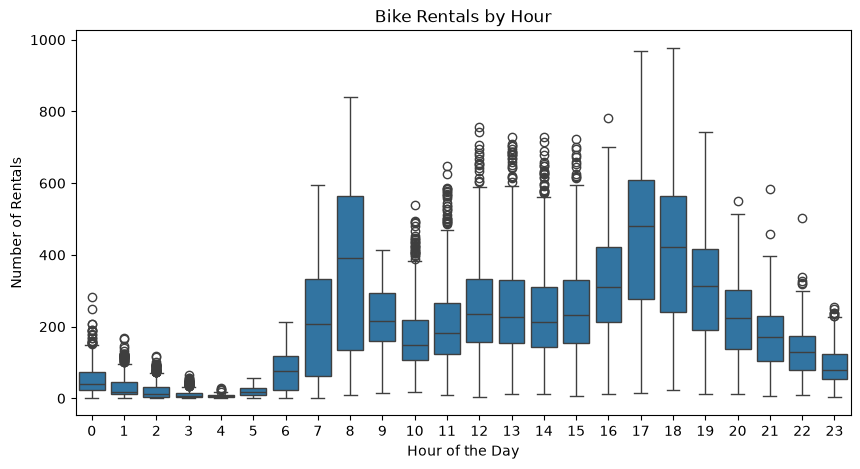

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.boxplot(data=train, x="hour", y="count")

plt.title("Bike Rentals by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Number of Rentals")

plt.show()

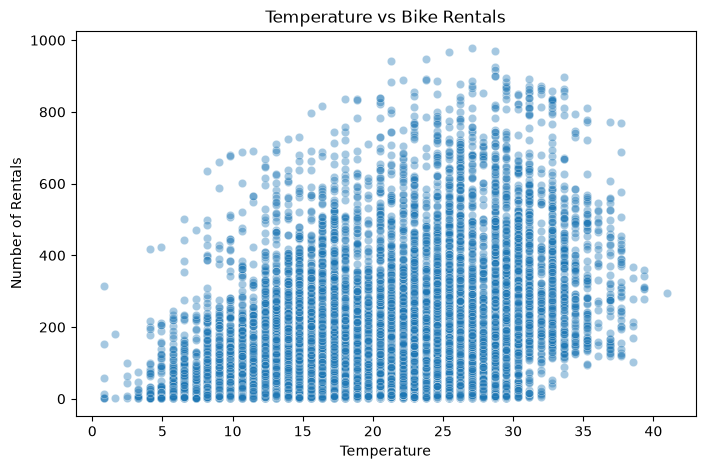

In [15]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=train, x="temp", y="count", alpha=0.4)

plt.title("Temperature vs Bike Rentals")
plt.xlabel("Temperature")
plt.ylabel("Number of Rentals")

plt.show()

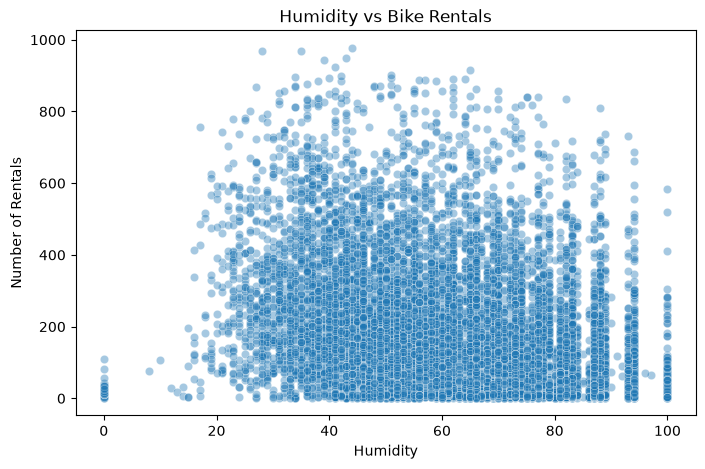

In [16]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=train, x="humidity", y="count", alpha=0.4)

plt.title("Humidity vs Bike Rentals")
plt.xlabel("Humidity")
plt.ylabel("Number of Rentals")

plt.show()

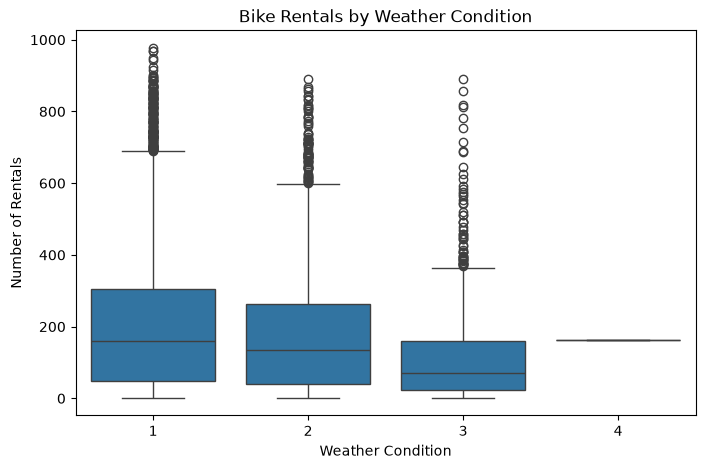

In [17]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=train, x="weather", y="count")

plt.title("Bike Rentals by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Number of Rentals")

plt.show()

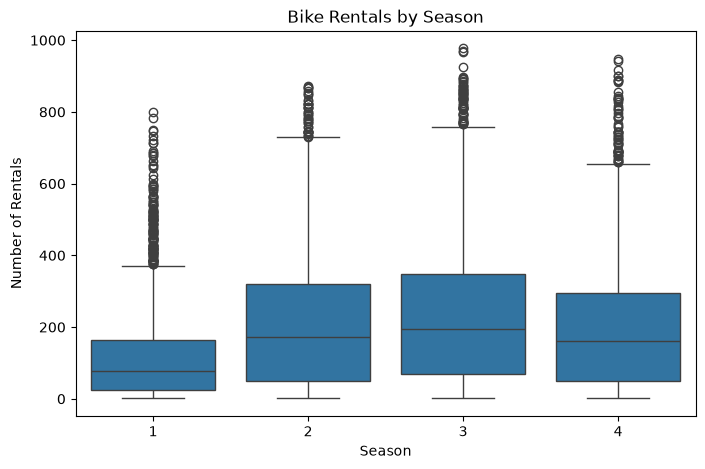

In [18]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=train, x="season", y="count")

plt.title("Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Number of Rentals")

plt.show()

Q3. Suggest which variables are likely to be most informative.

In [19]:
correlation = train.corr(numeric_only=True)["count"].sort_values(ascending=False)

print(correlation)

count         1.000000
registered    0.970948
casual        0.690414
hour          0.400601
temp          0.394454
atemp         0.389784
season        0.163439
windspeed     0.101369
workingday    0.011594
holiday      -0.005393
weather      -0.128655
humidity     -0.317371
Name: count, dtype: float64


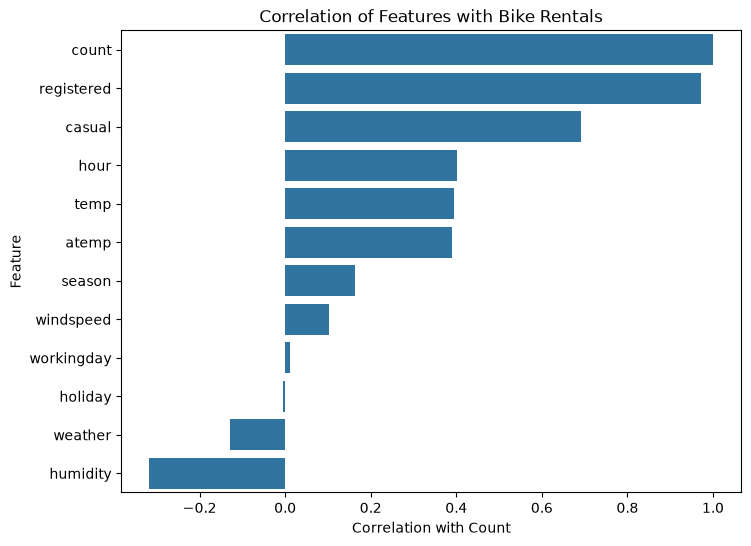

In [20]:
plt.figure(figsize=(8, 6))

sns.barplot(
    x=correlation.values,
    y=correlation.index
)

plt.title("Correlation of Features with Bike Rentals")
plt.xlabel("Correlation with Count")
plt.ylabel("Feature")

plt.show()

Based on the exploratory data analysis, hour is likely to be one of the most informative variables because bike rental demand varies substantially throughout the day, with particularly high demand during certain morning and evening hours.
temp is also likely to be an important predictor because the number of rentals generally increases with temperature up to a certain range. humidity appears to have an influence on rental demand as well.
Categorical variables such as season, weather, and workingday are also expected to provide useful information because bike demand can vary according to seasonal conditions, weather conditions, and whether the day is a working day.
Therefore, the important predictive variables are expected to include hour, temperature, humidity, weather, season, and workingday.
The variables casual and registered are excluded from the predictive features because they directly contribute to the target variable count and would result in data leakage.

Q4. You can try to derive features from datetime (hour, weekday, month, season), encode categorical variables, consider transformations to capture nonlinear trends to improve your model performance. If you do any of these, report it as answer to Q4. It is optional.

In [21]:
train["year"] = train["datetime"].dt.year
train["month"] = train["datetime"].dt.month
train["day"] = train["datetime"].dt.day
train["weekday"] = train["datetime"].dt.weekday

In [22]:
train[["datetime", "year", "month", "day", "hour", "weekday"]].head(10)

,datetime,year,month,day,hour,weekday
0,2011-01-01 00:00:00,2011,1,1,0,5
1,2011-01-01 01:00:00,2011,1,1,1,5
2,2011-01-01 02:00:00,2011,1,1,2,5
3,2011-01-01 03:00:00,2011,1,1,3,5
4,2011-01-01 04:00:00,2011,1,1,4,5
5,2011-01-01 05:00:00,2011,1,1,5,5
6,2011-01-01 06:00:00,2011,1,1,6,5
7,2011-01-01 07:00:00,2011,1,1,7,5
8,2011-01-01 08:00:00,2011,1,1,8,5
9,2011-01-01 09:00:00,2011,1,1,9,5


In [23]:
test["datetime"] = pd.to_datetime(test["datetime"])

test["year"] = test["datetime"].dt.year
test["month"] = test["datetime"].dt.month
test["day"] = test["datetime"].dt.day
test["hour"] = test["datetime"].dt.hour
test["weekday"] = test["datetime"].dt.weekday

In [24]:
features = [
    "season",
    "holiday",
    "workingday",
    "weather",
    "temp",
    "atemp",
    "humidity",
    "windspeed",
    "year",
    "month",
    "day",
    "hour",
    "weekday"
]

The datetime variable was converted into a datetime format and new features were extracted from it: year, month, day, hour, and weekday. These features provide more useful information about temporal patterns in bike rental demand.
The original datetime column is not directly used in the regression model. The engineered features allow the model to capture variations in demand according to time of day, day of the week, month, and year.

Q5. Split data into training and validation sets and build a simple Linear Regression model.

In [25]:
X = train[features]
y = train["count"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10886, 13)
y shape: (10886,)


In [26]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)

Training data: (8708, 13)
Validation data: (2178, 13)


In [27]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

LinearRegression()

In [28]:
y_pred_lr = lr_model.predict(X_val)

print(y_pred_lr[:10])

[247.47963048  48.19064523 201.06116009 292.82511262 389.91373765
 316.44093959 183.43600757 299.58993475 172.81617684  13.58825861]


In [29]:
y_pred_lr = np.maximum(y_pred_lr, 0)

In [30]:
def rmsle(actual, predicted):
    predicted = np.maximum(predicted, 0)
    
    return np.sqrt(
        np.mean(
            (np.log1p(predicted) - np.log1p(actual)) ** 2
        )
    )

In [31]:
lr_rmsle = rmsle(y_val, y_pred_lr)

print("Linear Regression RMSLE:", lr_rmsle)

Linear Regression RMSLE: 1.3070097243260648


Q6. To improve model performance, you may try to:
●	Extend feature space using polynomial transformations (degree 2 or 3)
●	Apply Ridge and Lasso regression on polynomial features, Tune the regularization strength (α).

In [32]:
from sklearn.preprocessing import PolynomialFeatures

In [33]:
poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train)
X_val_poly = poly.transform(X_val)

print("Original number of features:", X_train.shape[1])
print("Polynomial number of features:", X_train_poly.shape[1])

Original number of features: 13
Polynomial number of features: 104


In [34]:
poly_lr = LinearRegression()

poly_lr.fit(X_train_poly, y_train)

LinearRegression()

In [35]:
y_pred_poly = poly_lr.predict(X_val_poly)

y_pred_poly = np.maximum(y_pred_poly, 0)

In [36]:
poly_rmsle = rmsle(y_val, y_pred_poly)

print("Polynomial Regression (Degree 2) RMSLE:", poly_rmsle)

Polynomial Regression (Degree 2) RMSLE: 1.4104108827095838


Polynomial linear regression made it worse

In [37]:
#Ridge Regression 

In [38]:
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_poly, y_train)

y_pred_ridge = ridge_model.predict(X_val_poly)
y_pred_ridge = np.maximum(y_pred_ridge, 0)

ridge_rmsle = rmsle(y_val, y_pred_ridge)

print("Ridge Regression (Degree 2, alpha=1) RMSLE:", ridge_rmsle)

Ridge Regression (Degree 2, alpha=1) RMSLE: 1.3835404941165321


In [39]:
alphas = [0.01, 0.1, 1, 10, 100, 1000]

ridge_results = []

for alpha in alphas:
    model = Ridge(alpha=alpha)
    model.fit(X_train_poly, y_train)
    
    predictions = model.predict(X_val_poly)
    predictions = np.maximum(predictions, 0)
    
    score = rmsle(y_val, predictions)
    
    ridge_results.append((alpha, score))

ridge_results

[(0.01, 1.4045574083612171),
 (0.1, 1.3897950757253446),
 (1, 1.3835404941165321),
 (10, 1.3806288030750837),
 (100, 1.3748386492726248),
 (1000, 1.3784382471424614)]

In [40]:
ridge_results_df = pd.DataFrame(
    ridge_results,
    columns=["Alpha", "RMSLE"]
)

ridge_results_df

,Alpha,RMSLE
0,0.01,1.404557
1,0.10,1.389795
2,1.00,1.383540
3,10.00,1.380629
4,100.00,1.374839
5,1000.00,1.378438


In [41]:
best_ridge = ridge_results_df.loc[
    ridge_results_df["RMSLE"].idxmin()
]

print("Best Ridge alpha:", best_ridge["Alpha"])
print("Best Ridge RMSLE:", best_ridge["RMSLE"])

Best Ridge alpha: 100.0
Best Ridge RMSLE: 1.3748386492726248


In [42]:
#Fine Tuning Lasso Regression

In [44]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_poly_scaled = scaler.fit_transform(X_train_poly)
X_val_poly_scaled = scaler.transform(X_val_poly)

In [45]:
lasso_model = Lasso(alpha=0.1, max_iter=50000)

lasso_model.fit(X_train_poly_scaled, y_train)

y_pred_lasso = lasso_model.predict(X_val_poly_scaled)
y_pred_lasso = np.maximum(y_pred_lasso, 0)

lasso_rmsle = rmsle(y_val, y_pred_lasso)

print("Lasso Regression (Degree 2, alpha=0.1) RMSLE:", lasso_rmsle)

Lasso Regression (Degree 2, alpha=0.1) RMSLE: 1.372587440712687


C:\Users\sikda\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:678: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.460e+04, tolerance: 2.853e+04
  model = cd_fast.enet_coordinate_descent(


In [47]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso

lasso_model = make_pipeline(
    StandardScaler(),
    Lasso(alpha=1.0, max_iter=100000)
)

lasso_model.fit(X_train_poly, y_train)

y_pred_lasso = lasso_model.predict(X_val_poly)
y_pred_lasso = np.maximum(y_pred_lasso, 0)

lasso_rmsle = rmsle(y_val, y_pred_lasso)

print("Lasso Regression (Degree 2, alpha=1) RMSLE:", lasso_rmsle)

Lasso Regression (Degree 2, alpha=1) RMSLE: 1.3287206293292064


In [48]:
alphas = [0.1, 0.5, 1, 2, 5, 10]

lasso_results = []

for alpha in alphas:
    model = make_pipeline(
        StandardScaler(),
        Lasso(alpha=alpha, max_iter=100000)
    )
    
    model.fit(X_train_poly, y_train)
    
    predictions = model.predict(X_val_poly)
    predictions = np.maximum(predictions, 0)
    
    score = rmsle(y_val, predictions)
    
    lasso_results.append((alpha, score))

lasso_results_df = pd.DataFrame(
    lasso_results,
    columns=["Alpha", "RMSLE"]
)

lasso_results_df

,Alpha,RMSLE
0,0.1,1.372587
1,0.5,1.351219
2,1.0,1.328721
3,2.0,1.300858
4,5.0,1.250402
5,10.0,1.233273


In [49]:
best_lasso = lasso_results_df.loc[
    lasso_results_df["RMSLE"].idxmin()
]

print("Best Lasso alpha:", best_lasso["Alpha"])
print("Best Lasso RMSLE:", best_lasso["RMSLE"])

Best Lasso alpha: 10.0
Best Lasso RMSLE: 1.2332726232379831


Q7. Summarize all results (of different models tried out) in one table (RMSLE, key observations).

In [50]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Polynomial Regression (Degree 2)",
        "Ridge Regression (alpha=1)",
        "Ridge Regression (Best alpha=100)",
        "Lasso Regression (Best alpha=10)"
    ],
    "RMSLE": [
        rmsle(y_val, y_pred_lr),
        poly_rmsle,
        ridge_rmsle,
        best_ridge["RMSLE"],
        best_lasso["RMSLE"]
    ],
    "Observations": [
        "Baseline linear model",
        "Polynomial features increased complexity but performed worse",
        "Regularization improved polynomial regression slightly",
        "Best Ridge performance among tested alpha values",
        "Best overall model; regularization improved generalization"
    ]
})

results

,Model,RMSLE,Observations
0,Linear Regression,1.307010,Baseline linear model
1,Polynomial Regression (Degree 2),1.410411,Polynomial features increased complexity but p...
2,Ridge Regression (alpha=1),1.383540,Regularization improved polynomial regression ...
3,Ridge Regression (Best alpha=100),1.374839,Best Ridge performance among tested alpha values
4,Lasso Regression (Best alpha=10),1.233273,Best overall model; regularization improved ge...


Q8. Plot residuals for the best model.

In [51]:
# Train the best Lasso model again with alpha = 10

best_lasso_model = make_pipeline(
    StandardScaler(),
    Lasso(alpha=10, max_iter=100000)
)

best_lasso_model.fit(X_train_poly, y_train)

# Predictions
y_pred_best = best_lasso_model.predict(X_val_poly)

# Make sure predictions are non-negative
y_pred_best = np.maximum(y_pred_best, 0)

# Calculate residuals
residuals = y_val - y_pred_best

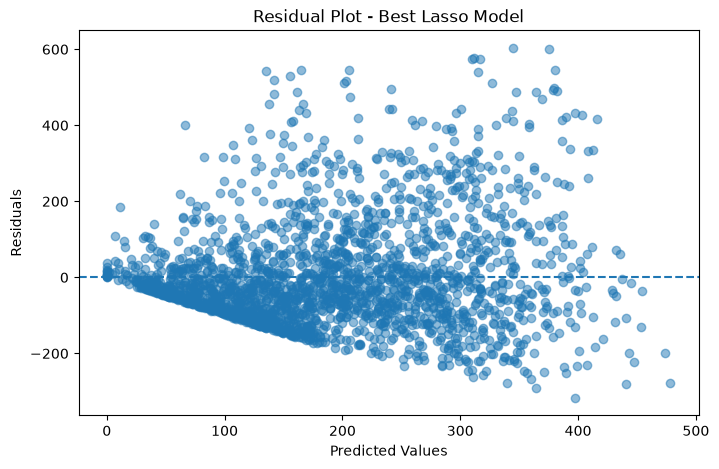

In [52]:
plt.figure(figsize=(8, 5))

plt.scatter(y_pred_best, residuals, alpha=0.5)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot - Best Lasso Model")

plt.show()

Q9. Explain why the winning model performs better.

Lasso Regression with α = 10 gave the best performance because regularization reduces the impact of less important features and helps prevent overfitting. This is especially useful with polynomial features, where the number of features increases. The model therefore generalizes better to the validation data and achieved the lowest RMSLE of 1.2333.

Q10. Why does RMSLE penalize under-predictions more gently than RMSE?

RMSLE is preferred over RMSE for bike-sharing demand prediction because the target variable, count, can vary greatly between low-demand and high-demand periods. RMSLE focuses on the relative difference between the actual and predicted values rather than only their absolute difference. It therefore reduces the influence of very large rental counts and is more suitable when we care about predicting demand proportionally. RMSLE also handles the skewed nature of bike rental demand better than RMSE.

Q11. What are the trade-offs between model simplicity and predictive power?

A simpler model is easier to understand, interpret, and implement, but it may not capture complex relationships in the data. More complex models, such as polynomial regression, can capture nonlinear relationships and potentially improve predictive performance, but they also increase the risk of overfitting and make the model harder to interpret. Therefore, the goal is to find a balance between simplicity and predictive performance. In this experiment, the Lasso model provided a good balance by using regularization to control model complexity while achieving the lowest RMSLE.

Q12. Why can’t Linear Regression alone capture time-of-day effects effectively?

Linear Regression assumes a linear relationship between the input features and the target. However, bike rental demand changes significantly throughout the day in a nonlinear way. For example, demand is generally low during the early morning, increases during the morning, and reaches a high level during commuting hours, with another peak in the evening. A single linear coefficient for hour cannot represent these multiple peaks and valleys. Therefore, additional feature engineering, such as one-hot encoding of hours, polynomial features, or other nonlinear models, can better capture the time-of-day pattern.

In [53]:
#Submission.csv

# Features and target
X_full = train[features]
y_full = train["count"]

X_test = test[features]

In [54]:
poly_final = PolynomialFeatures(degree=2, include_bias=False)

X_full_poly = poly_final.fit_transform(X_full)
X_test_poly = poly_final.transform(X_test)

In [55]:
final_lasso = make_pipeline(
    StandardScaler(),
    Lasso(alpha=10, max_iter=100000)
)

final_lasso.fit(X_full_poly, y_full)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('lasso', Lasso(alpha=10, max_iter=100000))])

In [56]:
test_predictions = final_lasso.predict(X_test_poly)

# Bike rental counts cannot be negative
test_predictions = np.maximum(test_predictions, 0)

In [57]:
submission = sample_submission.copy()

submission["count"] = test_predictions

submission.to_csv("Submission.csv", index=False)

print("Submission.csv created successfully!")
print(submission.head())

Submission.csv created successfully!
              datetime      count
0  2011-01-20 00:00:00  44.564272
1  2011-01-20 01:00:00  45.200417
2  2011-01-20 02:00:00  49.247949
3  2011-01-20 03:00:00  54.940603
4  2011-01-20 04:00:00  58.922482


In [58]:
print(submission.shape)
print(submission.columns)

(6493, 2)
Index(['datetime', 'count'], dtype='object')
